## Exercise 1

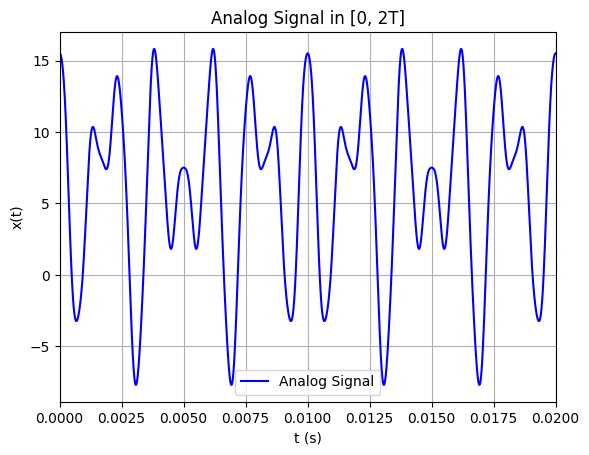

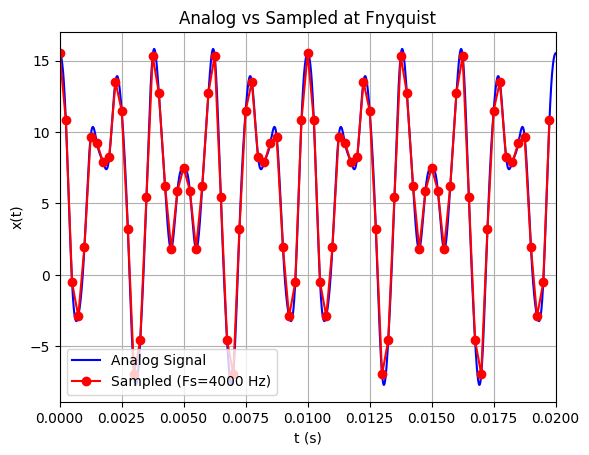

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

T = 0.01

t = np.arange(0, 2 * T, 0.000005)
x = (
    6
    - 2 * np.cos(600 * np.pi * t)
    + 6 * np.cos(1600 * np.pi * t)
    + 6 * np.cos(1000 * np.pi * t)
    - 0.5 * np.cos(4000 * np.pi * t)
)

plt.plot(t, x, "b-", label="Analog Signal")
plt.xlim(0, 2 * T)
plt.xlabel("t")
plt.ylabel("x(t)")
plt.title("Analog Signal in [0, 2T]")
plt.legend()
plt.grid()
plt.show()

Fnyquist = 4000

Ts = 1 / Fnyquist
tn = np.arange(0, 2 * T, Ts)
xn = (
    6
    - 2 * np.cos(600 * np.pi * tn)
    + 6 * np.cos(1600 * np.pi * tn)
    + 6 * np.cos(1000 * np.pi * tn)
    - 0.5 * np.cos(4000 * np.pi * tn)
)

plt.plot(t, x, "b-", label="Analog Signal")
plt.plot(tn, xn, "ro-", label="Sampled (Fs=4000 Hz)")
plt.xlim(0, 2 * T)
plt.xlabel("t")
plt.ylabel("x(t)")
plt.title("Analog vs Sampled at Fnyquist")
plt.legend()
plt.grid()
plt.show()

## Exercise 2

Zeros: [0.]
Poles: [1.2 0.5]
Pole magnitudes: [1.2 0.5]
ROC: |z| > 1.2


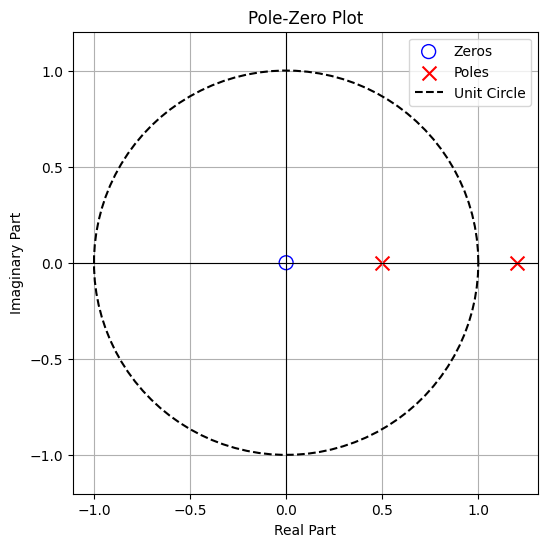

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

b = [0.5, 0]

a = [1, -1.7 * np.cos(16 * np.pi), 0.6]

z, p, c = signal.tf2zpk(b, a)
print("Zeros:", z)
print("Poles:", p)
print("Pole magnitudes:", np.abs(p))

print("ROC: |z| >", np.max(np.abs(p)))

plt.figure(figsize=(6, 6))

plt.scatter(np.real(z), np.imag(z), marker='o', s=100, facecolors='none', edgecolors='b', label='Zeros')
plt.scatter(np.real(p), np.imag(p), marker='x', s=100, color='r', label='Poles')

theta = np.linspace(0, 2 * np.pi, 100)
plt.plot(np.cos(theta), np.sin(theta), linestyle='--', color='black', label='Unit Circle')

plt.axhline(0, color='black', linewidth=0.8)
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel("Real Part")
plt.ylabel("Imaginary Part")
plt.title("Pole-Zero Plot")
plt.legend(loc='upper right')
plt.grid(True)
plt.axis('equal')
plt.show()

## Exercise 3

Filter order: 4
Cutoff frequency: 5920.019944820355 Hz


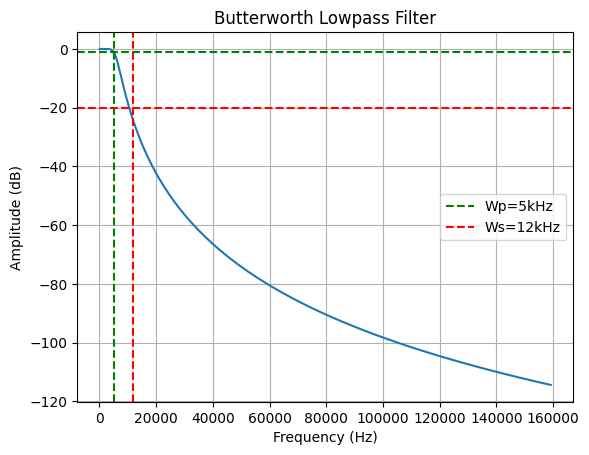

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

Ap = 1
As = 20
Wp = 5000
Ws = 12000

omega_p = 2 * np.pi * Wp
omega_s = 2 * np.pi * Ws

N, Wn = signal.buttord(omega_p, omega_s, Ap, As, analog=True)
b, a = signal.butter(N, Wn, "low", analog=True)
print(f"Filter order: {N}")
print(f"Cutoff frequency: {Wn/(2*np.pi)} Hz")

w, h = signal.freqs(b, a)

plt.plot(w / (2 * np.pi), 20 * np.log10(abs(h)))
plt.axvline(5000, color="green", linestyle="--", label="Wp=5kHz")
plt.axvline(12000, color="red", linestyle="--", label="Ws=12kHz")
plt.axhline(-1, color="green", linestyle="--")
plt.axhline(-20, color="red", linestyle="--")
plt.xlabel("Frequency")
plt.ylabel("Amplitude")
plt.title("Butterworth Lowpass Filter")
plt.legend()
plt.grid()
plt.show()

## Exercise 4

Filter order: 3
Cutoff frequency: 3999.9999999999995 Hz


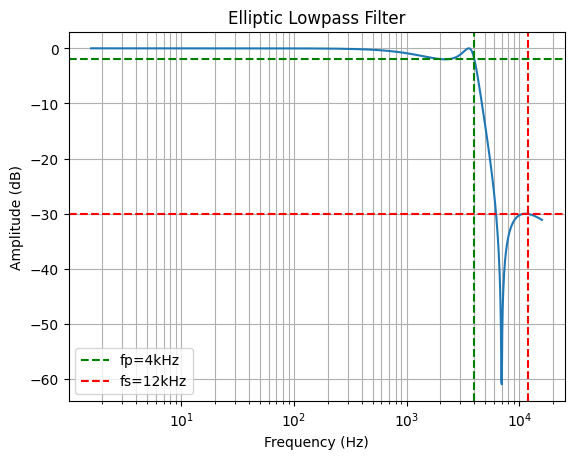

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

Rp = 2
Rs = 30
fp = 4000
fs = 12000

Wp = 2 * np.pi * fp
Ws = 2 * np.pi * fs

N, Wn = signal.ellipord(Wp, Ws, Rp, Rs, analog=True)
b, a = signal.ellip(N, Rp, Rs, Wn, btype="low", analog=True)
print(f"Filter order: {N}")
print(f"Cutoff frequency: {Wn/(2*np.pi)} Hz")

w, h = signal.freqs(b, a, worN=np.logspace(1, 5, 1000))

plt.semilogx(w / (2 * np.pi), 20 * np.log10(abs(h)))
plt.axvline(4000, color="green", linestyle="--", label="fp=4kHz")
plt.axvline(12000, color="red", linestyle="--", label="fs=12kHz")
plt.axhline(-2, color="green", linestyle="--")
plt.axhline(-30, color="red", linestyle="--")
plt.xlabel("Frequency")
plt.ylabel("Amplitude")
plt.title("Elliptic Lowpass Filter")
plt.legend()
plt.grid(which="both", axis="both")
plt.show()